<a href="https://colab.research.google.com/github/rontalapoojareddy/M.T-Project/blob/main/2_IDS_Research_V2_One_Cell_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Train / validation / untouched test: 140272 35069 82332
Raw / processed features: 42 192
Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: XGBoost
Training: DNN
Epoch 1/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - loss: 0.1876 - val_loss: 0.1334
Epoch 2/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1340 - val_loss: 0.1202
Epoch 3/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1278 - val_loss: 0.1183
Epoch 4/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1253 - val_loss: 0.1167
Epoch 5/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1224 - val_loss: 0.1153
Epoch 6/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1213 - val_loss: 0.1144
Epoch 7/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1195 - val_loss: 0.1144
Epoch 8/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1190 - val_loss: 0.1129
Epoch 9/20
274/274 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1177 - val_loss: 0.1123
Epoch 10/20
274/274 ━━━━━

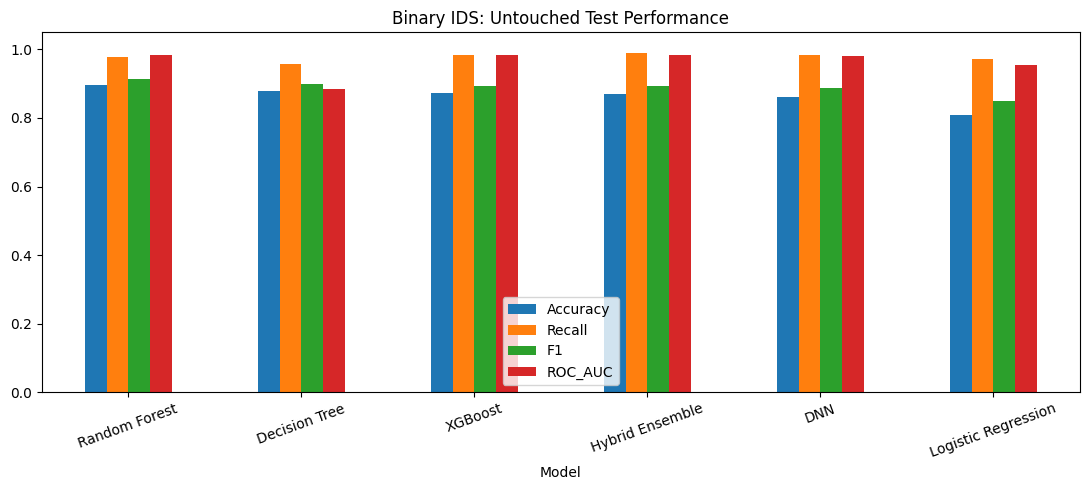


Multiclass validation macro-F1: {'Baseline RF': 0.5508630007136356, 'Balanced RF': 0.5775019449795226} Chosen: Balanced RF

MULTICLASS TEST REPORT
                 precision    recall  f1-score   support

      Analysis       0.04      0.04      0.04       677
      Backdoor       0.04      0.32      0.07       583
           DoS       0.30      0.20      0.24      4089
      Exploits       0.82      0.64      0.72     11132
       Fuzzers       0.81      0.77      0.79      6062
       Generic       1.00      0.96      0.98     18871
Reconnaissance       0.87      0.83      0.85      3496
     Shellcode       0.33      0.85      0.48       378
         Worms       0.59      0.50      0.54        44

      accuracy                           0.75     45332
     macro avg       0.53      0.57      0.52     45332
  weighted avg       0.82      0.75      0.78     45332

Multiclass macro-F1: 0.5222147391435003

END-TO-END LABEL REPORT (includes missed attacks)
                 precision   

In [1]:
# RESEARCH V2 — SINGLE GOOGLE COLAB CELL
# Based on MTech_XAI_Intrusion_Detection.ipynb; original notebook remains unchanged.
# This is a NEW experiment. Do not reuse previous performance numbers as its results.
import sys, subprocess, os, random, warnings, json, time
warnings.filterwarnings("ignore")
subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                       "xgboost", "shap", "gradio", "joblib"])
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
OUT = Path("/content/ids_research_v2")
OUT.mkdir(parents=True, exist_ok=True)
RUN_SHAP = False         # Change to True for SHAP (takes additional time)
LAUNCH_GRADIO = False    # Change to True for a temporary demo link
VAL_SIZE = .20

# Official UNSW-NB15 split used in your original notebook.
DATA = Path("/content/unsw_nb15")
DATA.mkdir(exist_ok=True)
TRAIN = DATA / "UNSW_NB15_training-set.csv"
TEST  = DATA / "UNSW_NB15_testing-set.csv"
BASE = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/"
for file in (TRAIN, TEST):
    if not file.exists():
        import requests
        try:
            response = requests.get(BASE + file.name, timeout=120)
            response.raise_for_status()
            file.write_bytes(response.content)
        except Exception as e:
            print("Automatic download unavailable:", e)
            print("Upload the TWO UNSW-NB15 CSV files when prompted.")
            from google.colab import files
            uploaded = files.upload()
            for name, content in uploaded.items():
                (DATA / name).write_bytes(content)
            break
if not TRAIN.exists() or not TEST.exists():
    raise FileNotFoundError("Both official training and testing CSVs are required in " + str(DATA))
train_df, test_df = pd.read_csv(TRAIN), pd.read_csv(TEST)
assert {"label","attack_cat"}.issubset(train_df.columns)
assert {"label","attack_cat"}.issubset(test_df.columns)
FEATURES = [c for c in train_df.columns if c not in ("id","label","attack_cat")]
assert set(FEATURES).issubset(test_df.columns)
X_full = train_df[FEATURES].copy()
y_full = train_df["label"].astype(int)
X_test = test_df[FEATURES].copy()
y_test = test_df["label"].astype(int)
# Split BEFORE preprocessing or model fitting. Validation is not part of training.
idx_train, idx_val = train_test_split(
    np.arange(len(train_df)), test_size=VAL_SIZE, stratify=y_full, random_state=SEED)
X_train, X_val = X_full.iloc[idx_train], X_full.iloc[idx_val]
y_train, y_val = y_full.iloc[idx_train], y_full.iloc[idx_val]
categorical = X_train.select_dtypes(include=["object","category"]).columns.tolist()
numeric = [c for c in FEATURES if c not in categorical]
prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical)
])
Xt = prep.fit_transform(X_train)
Xv = prep.transform(X_val)
Xe = prep.transform(X_test)
print("Train / validation / untouched test:", len(X_train), len(X_val), len(X_test))
print("Raw / processed features:", len(FEATURES), Xt.shape[1])

models = {
 "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
 "Decision Tree": DecisionTreeClassifier(max_depth=25, min_samples_leaf=2,
                                        class_weight="balanced", random_state=SEED),
 "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=25,
                         min_samples_split=5, min_samples_leaf=2,
                         class_weight="balanced", n_jobs=-1, random_state=SEED),
 "XGBoost": XGBClassifier(n_estimators=300, max_depth=8, learning_rate=.08,
                         subsample=.8, colsample_bytree=.8,
                         objective="binary:logistic", eval_metric="logloss",
                         tree_method="hist", n_jobs=-1, random_state=SEED)
}
for name, model in models.items():
    print("Training:", name)
    model.fit(Xt, y_train)

# DNN is trained on training data only; validation is used for early stopping.
def dense(a):
    return a.toarray().astype("float32") if hasattr(a,"toarray") else np.asarray(a,dtype="float32")
Xt_nn, Xv_nn, Xe_nn = dense(Xt), dense(Xv), dense(Xe)
nn = keras.Sequential([
 layers.Input(shape=(Xt_nn.shape[1],)),
 layers.Dense(128,activation="relu"), layers.BatchNormalization(), layers.Dropout(.30),
 layers.Dense(64,activation="relu"), layers.BatchNormalization(), layers.Dropout(.20),
 layers.Dense(32,activation="relu"), layers.Dense(1,activation="sigmoid")])
nn.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),
           loss="binary_crossentropy")
print("Training: DNN")
nn.fit(Xt_nn, y_train.to_numpy(), validation_data=(Xv_nn,y_val.to_numpy()),
       epochs=20,batch_size=512,verbose=1,
       callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,
                                                restore_best_weights=True)])
def probabilities(matrix, matrix_nn):
    result={name: model.predict_proba(matrix)[:,1] for name,model in models.items()}
    result["DNN"]=nn.predict(matrix_nn,verbose=0).ravel()
    return result
val_p = probabilities(Xv, Xv_nn)

# Optimize ONLY on held-out validation data. Fixed small grid limits overfitting.
# Optimization target: binary validation F1; test set is NEVER used for selection.
weight_candidates = [(0.50,0.25,0.25),(0.60,0.20,0.20),
                     (0.40,0.30,0.30),(0.34,0.33,0.33),
                     (0.70,0.15,0.15)]
thresholds = np.arange(.30,.701,.05)
best = None
for weights in weight_candidates:
    pv = (weights[0]*val_p["Random Forest"]+
          weights[1]*val_p["XGBoost"]+weights[2]*val_p["DNN"])
    for threshold in thresholds:
        score = f1_score(y_val, pv>=threshold, zero_division=0)
        if best is None or score>best["validation_f1"]:
            best={"weights":weights,"threshold":float(threshold),
                  "validation_f1":float(score)}
print("Selected on validation only:",best)
test_p = probabilities(Xe,Xe_nn)
test_p["Hybrid Ensemble"] = (
    best["weights"][0]*test_p["Random Forest"]+
    best["weights"][1]*test_p["XGBoost"]+
    best["weights"][2]*test_p["DNN"])
rows=[]
for name,proba in test_p.items():
    threshold=best["threshold"] if name=="Hybrid Ensemble" else .5
    pred=(proba>=threshold).astype(int)
    rows.append(dict(Model=name, Accuracy=accuracy_score(y_test,pred),
                     Precision=precision_score(y_test,pred,zero_division=0),
                     Recall=recall_score(y_test,pred,zero_division=0),
                     F1=f1_score(y_test,pred,zero_division=0),
                     ROC_AUC=roc_auc_score(y_test,proba)))
binary_results=pd.DataFrame(rows).sort_values("F1",ascending=False)
print("\nBINARY TEST RESULTS (new experiment)\n",binary_results.round(4).to_string(index=False))
binary_results.to_csv(OUT/"binary_test_results.csv",index=False)
ax=binary_results.set_index("Model")[["Accuracy","Recall","F1","ROC_AUC"]].plot(
    kind="bar",figsize=(11,5),rot=20,title="Binary IDS: Untouched Test Performance")
ax.set_ylim(0,1.05); plt.tight_layout()
plt.savefig(OUT/"binary_comparison.png",dpi=180); plt.show(); plt.close()

# MULTICLASS RESEARCH BASELINE — attack records only.
# Use the SAME training/validation split; do not fit multiclass on test records.
attack_tr = train_df.iloc[idx_train].query("label == 1")
attack_va = train_df.iloc[idx_val].query("label == 1")
attack_te = test_df.query("label == 1")
Xm_tr=prep.transform(attack_tr[FEATURES])
Xm_va=prep.transform(attack_va[FEATURES])
Xm_te=prep.transform(attack_te[FEATURES])
ym_tr=attack_tr["attack_cat"].astype(str).str.strip()
ym_va=attack_va["attack_cat"].astype(str).str.strip()
ym_te=attack_te["attack_cat"].astype(str).str.strip()
# Compare baseline vs balanced learning on validation; no test-based choice.
multi_models = {
 "Baseline RF":RandomForestClassifier(n_estimators=200,max_depth=25,
                 min_samples_split=5,min_samples_leaf=2,n_jobs=-1,random_state=SEED),
 "Balanced RF":RandomForestClassifier(n_estimators=200,max_depth=25,
                 min_samples_split=5,min_samples_leaf=2,n_jobs=-1,random_state=SEED)
}
multi_models["Baseline RF"].fit(Xm_tr,ym_tr)
multi_models["Balanced RF"].fit(Xm_tr,ym_tr,
    sample_weight=compute_sample_weight("balanced",ym_tr))
val_scores={name:f1_score(ym_va,model.predict(Xm_va),average="macro",zero_division=0)
            for name,model in multi_models.items()}
winner=max(val_scores,key=val_scores.get)
attack_model=multi_models[winner]
print("\nMulticlass validation macro-F1:",val_scores,"Chosen:",winner)
multi_pred=attack_model.predict(Xm_te)
multi_report=classification_report(ym_te,multi_pred,zero_division=0,output_dict=True)
print("\nMULTICLASS TEST REPORT\n",classification_report(ym_te,multi_pred,zero_division=0))
pd.DataFrame(multi_report).T.to_csv(OUT/"multiclass_test_report.csv")
print("Multiclass macro-F1:",f1_score(ym_te,multi_pred,average="macro",zero_division=0))
# Full pipeline evaluation: binary false negatives also affect attack-type recall.
chosen_binary=binary_results.iloc[0]["Model"]
chosen_binary_threshold=best["threshold"] if chosen_binary=="Hybrid Ensemble" else .5
all_binary=(test_p[chosen_binary]>=chosen_binary_threshold).astype(int)
attack_only_indices=np.where(all_binary==1)[0]
full_prediction=np.array(["Normal"]*len(test_df),dtype=object)
if len(attack_only_indices):
    full_prediction[attack_only_indices]=attack_model.predict(
        prep.transform(X_test.iloc[attack_only_indices]))
true_full=np.where(y_test.to_numpy()==0,"Normal",
                   test_df["attack_cat"].astype(str).str.strip().to_numpy())
print("\nEND-TO-END LABEL REPORT (includes missed attacks)\n",
      classification_report(true_full,full_prediction,zero_division=0))
pd.DataFrame({"True":true_full,"Predicted":full_prediction}).to_csv(
    OUT/"end_to_end_test_predictions.csv",index=False)

# SHAP explains XGBoost, not the deployed Random Forest.
if RUN_SHAP:
    try:
        import shap
        explain_n=min(300,len(Xe))
        sample=Xe[:explain_n]
        if hasattr(sample,"toarray"): sample=sample.toarray()
        explainer=shap.TreeExplainer(models["XGBoost"])
        values=explainer(sample)
        shap.summary_plot(values.values,sample,
                          feature_names=prep.get_feature_names_out(),show=False,
                          max_display=20)
        plt.tight_layout(); plt.savefig(OUT/"shap_xgboost.png",dpi=180,bbox_inches="tight")
        plt.show(); plt.close()
    except Exception as e:
        print("Optional SHAP visualization failed:",repr(e))

# Save trained artifacts and exact feature order.
joblib.dump({"preprocessor":prep,"binary_models":models,
             "attack_model":attack_model,"features":FEATURES,
             "best_binary":chosen_binary,"ensemble_selection":best},
            OUT/"research_models.joblib")
nn.save(str(OUT/"dnn.keras"))
(OUT/"run_metadata.json").write_text(json.dumps({
    "seed":SEED,"validation_fraction":VAL_SIZE,
    "validation_f1_hybrid":best["validation_f1"],
    "hybrid_weights":best["weights"],"hybrid_threshold":best["threshold"],
    "chosen_binary_model":chosen_binary,
    "multiclass_validation_scores":val_scores,
    "dataset_train_rows":len(train_df),"dataset_test_rows":len(test_df),
    "raw_features":len(FEATURES),"processed_features":int(Xt.shape[1])
},indent=2))
def predict_new_csv(csv_path):
    data=pd.read_csv(csv_path)
    missing=[c for c in FEATURES if c not in data.columns]
    if missing: raise ValueError("Missing columns: "+str(missing))
    Z=prep.transform(data[FEATURES])
    if chosen_binary=="Hybrid Ensemble":
        p=(best["weights"][0]*models["Random Forest"].predict_proba(Z)[:,1]+
           best["weights"][1]*models["XGBoost"].predict_proba(Z)[:,1]+
           best["weights"][2]*nn.predict(dense(Z),verbose=0).ravel())
        th=best["threshold"]
    elif chosen_binary=="DNN":
        p=nn.predict(dense(Z),verbose=0).ravel(); th=.5
    else:
        p=models[chosen_binary].predict_proba(Z)[:,1]; th=.5
    attack=(p>=th)
    types=np.array(["Normal"]*len(data),dtype=object)
    if attack.any(): types[attack]=attack_model.predict(Z[attack])
    result=data.copy()
    result["Prediction"]=np.where(attack,"Attack","Normal")
    result["Attack_Probability"]=p
    result["Attack_Type"]=types
    return result
if LAUNCH_GRADIO:
    import gradio as gr
    def demo(file):
        if file is None: raise gr.Error("Upload a CSV first.")
        result=predict_new_csv(file)
        dest=str(OUT/"latest_predictions.csv")
        result.to_csv(dest,index=False)
        return result.head(100),dest
    with gr.Blocks() as app:
        gr.Markdown("# Explainable IDS Research V2 — CSV Batch Prediction")
        uploaded=gr.File(label="Network traffic CSV",file_types=[".csv"],type="filepath")
        run=gr.Button("Analyze")
        table=gr.Dataframe(label="First 100 predictions")
        download=gr.File(label="Download full results")
        run.click(demo,inputs=uploaded,outputs=[table,download])
    app.launch(share=True)
print("\nDONE. Outputs saved in:",OUT)
print("IMPORTANT: New metrics must be verified; do not copy older notebook results into the paper.")


In [2]:
import os

folder = "/content/ids_research_v2"

for file in os.listdir(folder):
    print(file)

research_models.joblib
end_to_end_test_predictions.csv
dnn.keras
run_metadata.json
binary_test_results.csv
binary_comparison.png
multiclass_test_report.csv


In [3]:
import pandas as pd

folder = "/content/ids_research_v2"

print("========== BINARY RESULTS ==========")
binary = pd.read_csv(
    folder + "/binary_test_results.csv"
)
print(binary.to_string(index=False))

print("\n========== MULTICLASS RESULTS ==========")
multi = pd.read_csv(
    folder + "/multiclass_test_report.csv"
)
print(multi.to_string(index=False))

========== BINARY RESULTS ==========
              Model  Accuracy  Precision   Recall       F1  ROC_AUC
      Random Forest  0.897476   0.856263 0.977963 0.913075 0.984508
      Decision Tree  0.879816   0.844189 0.958661 0.897791 0.885325
            XGBoost  0.872516   0.820939 0.982838 0.894623 0.983751
    Hybrid Ensemble  0.870937   0.815670 0.989125 0.894062 0.984524
                DNN  0.862605   0.808499 0.983389 0.887409 0.979837
Logistic Regression  0.809248   0.753270 0.971896 0.848730 0.955307

========== MULTICLASS RESULTS ==========
    Unnamed: 0  precision   recall  f1-score      support
      Analysis   0.037084 0.042836  0.039753   677.000000
      Backdoor   0.036690 0.315609  0.065738   583.000000
           DoS   0.304464 0.195158  0.237854  4089.000000
      Exploits   0.821317 0.635465  0.716536 11132.000000
       Fuzzers   0.806614 0.768558  0.787126  6062.000000
       Generic   0.999725 0.962270  0.980640 18871.000000
Reconnaissance   0.871787 0.834382  0.8

In [4]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/IDS_Research_Results",
    "zip",
    "/content/ids_research_v2"
)

files.download("/content/IDS_Research_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>